In [27]:
import requests
import json

USERNAME = "splashling"
PASSWORD = "Pitaspitas123!"

FECHA_INICIO = "01-01-2024"
FECHA_FIN = "12-31-2024"
CAPA = "Geophysical_Data_sm_surface"
LATITUD = 16.42
LONGITUD = 9.06

In [34]:

layers = requests.get(
    "https://appeears.earthdatacloud.nasa.gov/api/product/NASADEM_NC.001"
).json()
print(layers)

{'NASADEM_HGT': {'AddOffset': '', 'Available': True, 'DataType': 'int16', 'Description': 'Elevation', 'Dimensions': ['time', 'lat', 'lon'], 'FillValue': -32768, 'FillValueAll': [-32768], 'Group': '', 'Info': {}, 'IsQA': False, 'Layer': 'NASADEM_HGT', 'OrigDataType': 'int16', 'OrigValidMax': 32767, 'OrigValidMin': -32767, 'QualityLayers': "['NASADEM_NUM']", 'QualityProductAndVersion': 'NASADEM_NC.001', 'ScaleFactor': '', 'Units': 'Meters', 'ValidMax': 32767, 'ValidMin': -32767, 'XSize': 3601, 'YSize': 3601}}


In [29]:

# Login
r = requests.post(
    "https://appeears.earthdatacloud.nasa.gov/api/login",
    auth=(USERNAME, PASSWORD)
)

token = r.json()["token"]

headers = {
    "Authorization": f"Bearer {token}"
}

task = {
    "task_type": "point",
    "task_name": "Agricultura_Murcia",
    "params": {
        "dates": [
            {
                "startDate": FECHA_INICIO,
                "endDate": FECHA_FIN
            }
        ],
        "layers": [
            {
                "product": "SPL4SMGP.008",
                "layer": "Geophysical_Data_sm_surface"
            },
            {
                "product": "SPL4SMGP.008",
                "layer": "Geophysical_Data_sm_rootzone"
            },
            {
                "product": "NASADEM_NC.001",
                "layer": "Elevation"
            }
        ],
        "coordinates": [
            {
                "latitude": LATITUD,
                "longitude": LONGITUD
            }
        ]
    }
}

r = requests.post(
    "https://appeears.earthdatacloud.nasa.gov/api/task",
    headers=headers,
    json=task
)

print(r.json())

{'task_id': '34d872e3-2bda-4f4c-bb80-ed7efb9abc03', 'status': 'pending'}


In [41]:
task_id = r.json()["task_id"]

status_url = f"https://appeears.earthdatacloud.nasa.gov/api/task/{task_id}"

while True:
    status = requests.get(status_url, headers=headers).json()

    print(status["status"])

    if status["status"] == "done":
        break

processing
processing
processing
processing
processing


KeyboardInterrupt: 

In [23]:
from io import StringIO
import pandas as pd
import matplotlib.pyplot as plt

r = requests.get(
    f"https://appeears.earthdatacloud.nasa.gov/api/bundle/{task_id}",
    headers=headers
)

r.raise_for_status()

files = r.json()["files"]

csv_file = next(
    f for f in files
    if f["file_name"].endswith(".csv")
)

file_id = csv_file["file_id"]

url = f"https://appeears.earthdatacloud.nasa.gov/api/bundle/{task_id}/{file_id}"

csv_text = requests.get(
    url,
    headers=headers
).text

df = pd.read_csv(StringIO(csv_text))

# ====================================
# GUARDAR RESULTADO
# ====================================

df.to_csv("soil_moisture_daily.csv", index=False)

print(df.head())
print("\nArchivo guardado: soil_moisture_daily.csv")

   Latitude  Longitude                     Date SMAP_Tile  \
0     37.99      -1.13  2024-01-01 01:30:00 UTC    h00v00   
1     37.99      -1.13  2024-01-01 04:30:00 UTC    h00v00   
2     37.99      -1.13  2024-01-01 07:30:00 UTC    h00v00   
3     37.99      -1.13  2024-01-01 10:30:00 UTC    h00v00   
4     37.99      -1.13  2024-01-01 13:30:00 UTC    h00v00   

   SPL4SMGP_008_Line_Y_9.00805km  SPL4SMGP_008_Sample_X_9.00805km  \
0                          311.0                           1915.0   
1                          311.0                           1915.0   
2                          311.0                           1915.0   
3                          311.0                           1915.0   
4                          311.0                           1915.0   

   SPL4SMGP_008_Geophysical_Data_sm_surface  
0                                  0.067293  
1                                  0.070032  
2                                  0.069048  
3                                 

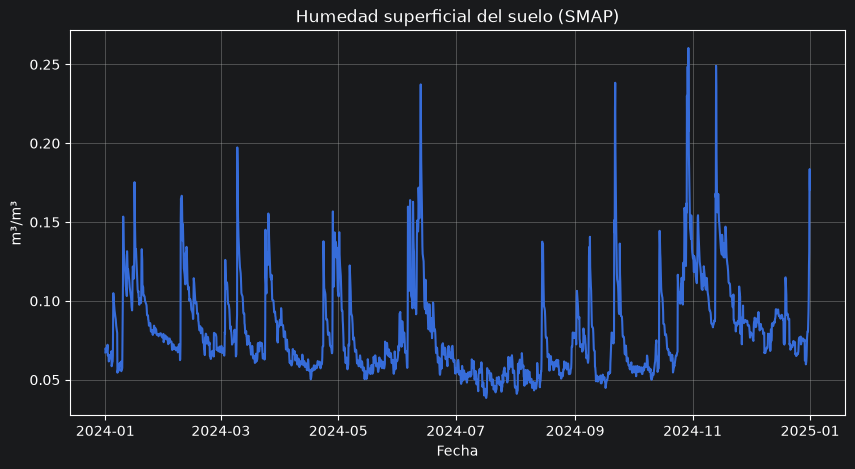

In [26]:


df = pd.read_csv("soil_moisture_daily.csv")

df["Date"] = pd.to_datetime(df["Date"])

plt.figure(figsize=(10,5))
plt.plot(df["Date"], df["SPL4SMGP_008_Geophysical_Data_sm_surface"])

plt.title("Humedad superficial del suelo (SMAP)")
plt.xlabel("Fecha")
plt.ylabel("m³/m³")
plt.grid(True)

plt.show()